# Magnitude Spectrum Manipulation / Crude Filtering

<br/>

> The MIR Book also mentions Analog and Digital Filtering? Could look into this, this would be P5 (advanced)

<br/>

### Magnitude Spectrum Manipulation
Magnitude Spectrum Manipulation consists of manipulating the frequency domain representation of a signal in different ways (MIR Book).

<br/>

### Crude Filtering
Crude Filtering is one application of Magnitude Spectrum Manipulation where certain frequencies (i.e., a percentage of the magnitude spectrum) are set to zero, causing the frequencies in that range to disappear (MIR Book).

<br/>

### Four Families of Filtering
There are four main families of filtering effects (Reveillac, 2018).

1. **High-pass filters:** Allows only frequencies above a frequency threshold (called the cut-off frequency) through the filter. Used to **reduce low frequencies**. (Reveillac, 2018)
2. **Low-pass filters:** Opposite of high-pass: allows only frequencies below the cut-off frequency through the filter. Used to **reduce high frequencies**. (Reveillac, 2018)
3. **Band-pass filters:** Allows only frequencies between an upper threshold and a lower threshold through the filter. Often used **to isolate a specific part of the audio signal**. (Reveillac, 2018)
4. **Band-stop filters or band-rejection filters:** Removes the frequencies between a lower threshold and an upper threshold, and keeps the frequencies outside of it. Used to reduce a certain frequency band to eliminate undesirable noises. Sometimes called band limit filters, bell filters, band-elimination filters and T-notch filters. (Reveillac, 2018)

#### References:


*   Magnitude spectrum manipulation and crude filtering in MIR Book: https://github.com/gtzan/mir_book/blob/master/ch1_sinusoidworld/Explaining_the_DFT_a_music_perspective_part6.ipynb
*   Réveillac, J.-M. (2018). Filtering Effects. In Musical Sound Effects (pp. 81–104). John Wiley & Sons, Incorporated. https://doi.org/10.1002/9781119467014.ch4



In [ ]:
import IPython.display as ipd
import numpy as np
import scipy.fft as fft
from scipy.io import wavfile
from scipy.io.wavfile import write
import matplotlib.pyplot as plt

# use this filename when working locally
# filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner = wavfile.read(filename)
ipd.Audio(tomsdiner, rate=srate)

In [59]:
def save_audio_to_wav(filename, audio, srate=44100):
  """Saves an audio array as a wav file"""
  audio = audio / np.max(np.abs(audio))
  write(filename, srate, audio.astype(np.float32))

def crude_filtering(signal: np.ndarray, frequency_range: tuple[float, float]) -> np.ndarray:
  '''
  Crude filtering on a signal.

  This function takes the input signal, converts that signal from a time domain
  to a frequency domain using the DFT, then zeroes out frequencies within the
  threshold given. The signal is then converted back to time domain
  using the inverse DFT and returned.

  Args:
    signal (np.ndarray): the samples of the signal
    threshold (tuple): the lower and upper frequency percentages (represented by floats 0.0:1.0)

  Returns:
    np.ndarray: the filtered signal
  '''
  # Convert the time-domain audio signal to a frequency-domain array of complex coefficients using fft
  # We use rfft because the audio samples are real-valued, so rfft returns only non-negative frequencies and avoids redundant info
  # makes it easier to isolate the range of frequencies (only have to do it once for non-negative frequencies)
  complex_spectrum = fft.rfft(signal)
  # Calculate the magnitude (absolute value) of each complex FFT coefficient
  magnitude_spectrum = np.abs(complex_spectrum)

  # Using frequency bins, we can isolate the range of frequencies we would like to remove
  num_bins = len(magnitude_spectrum)
  start = (frequency_range[0] * num_bins)
  end = (frequency_range[1] * num_bins)
  # Set the frequencies within the frequency range to zero, to remove those frequencies from the signal
  magnitude_spectrum[int(start):int(end)] = 0.0

  # Calculate the phase spectrum and recalculate the new complex magnitude spectrum to
  # prepare for reconstructing the signal back to the time domain
  phase_spectrum = np.angle(complex_spectrum)
  reconstructed_complex_spectrum = magnitude_spectrum * (np.cos(phase_spectrum)+1j*np.sin(phase_spectrum))

  # Use the inverse FFT to reconstruct the signal back to the time domain
  reconstructed_signal = fft.irfft(reconstructed_complex_spectrum)

  return reconstructed_signal


def band_pass_crude_filtering(signal: np.ndarray, frequency_range: tuple[float, float]) -> np.ndarray:
  '''
  Band-pass filtering on a signal.
  Uses the frequency range to calculate a lower frequency range and an upper frequency
  range. Then the crude_filtering function is used on the signal twice with each
  range to filter out the lower and upper ranges so that the final signal only contains
  the frequencies WITHIN the frequency range given to properly do band pass filtering.

  Args:
    signal (np.ndarray): the samples of the signal
    threshold (tuple): the lower and upper frequency percentages (represented by floats

  Returns:
    np.ndarray: the filtered signal
  '''
  lower_frequency_range = (0.0, frequency_range[0])
  upper_frequency_range = (frequency_range[1], 1.0)

  # filter out the frequencies in the lower frequency range
  lower_filtered_signal = crude_filtering(signal, lower_frequency_range)
  # filter out the freqs in the upper range of the lower_filtered_signal so that
  # final signal contains both ranges filtered out
  band_pass_filtered_signal = crude_filtering(lower_filtered_signal, upper_frequency_range)

  return band_pass_filtered_signal

low_pass = (0.10, 1.00)
high_pass = (0.0, 0.35)
band_stop = (0.250, 0.75)
band_pass = (0.20, 0.70)


In [60]:
low_pass_toms_diner = crude_filtering(tomsdiner, low_pass)
ipd.Audio(low_pass_toms_diner, rate=srate) # this one sounds like a muffled version
# save audio
save_audio_to_wav('audios/mag_spec_man_low_pass.wav', low_pass_toms_diner, srate)

In [61]:
high_pass_toms_diner = crude_filtering(tomsdiner, high_pass)
ipd.Audio(high_pass_toms_diner, rate=srate) # this one kind of sounds like morroccas!
# save audio
save_audio_to_wav('audios/mag_spec_man_high_pass.wav', high_pass_toms_diner, srate)

In [62]:
band_stop_toms_diner = crude_filtering(tomsdiner, band_stop)
ipd.Audio(band_stop_toms_diner, rate=srate)
# save audio
save_audio_to_wav('audios/mag_spec_man_band_stop.wav', band_stop_toms_diner, srate)

In [63]:
band_pass_toms_diner = band_pass_crude_filtering(tomsdiner, band_pass)
ipd.Audio(band_pass_toms_diner, rate=srate)
# save audio
save_audio_to_wav('audios/mag_spec_man_band_pass.wav', band_stop_toms_diner, srate)

## Plots
Since each frequency in the song contributes to the audio, when frequencies are removed by a filter, the frequencies that contribute to certain amplitudes are now gone.

Removing different frequencies changes the appearance of the amplitude plot.

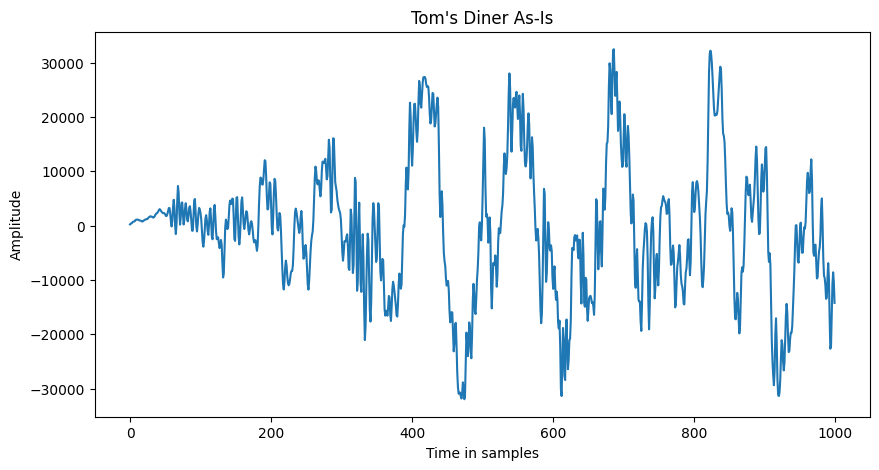

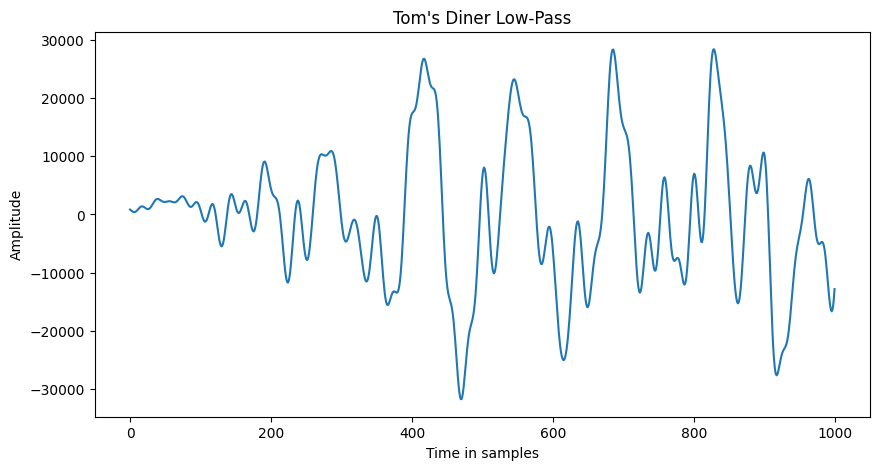

In [64]:
fig = plt.figure(figsize=(10, 5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Tom's Diner As-Is")
plt.plot(tomsdiner[0:1000])
plt.savefig('plots/orignal_toms_diner.png')
plt.show()

fig = plt.figure(figsize=(10, 5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Tom's Diner Low-Pass")
# Notice this wave form looks smoother, because high frequencies are removed
# high frequencies are usually responsible for faster oscillations in amplitude
plt.plot(low_pass_toms_diner[0:1000])
plt.savefig('plots/low_pass_toms_diner.png')
plt.show()

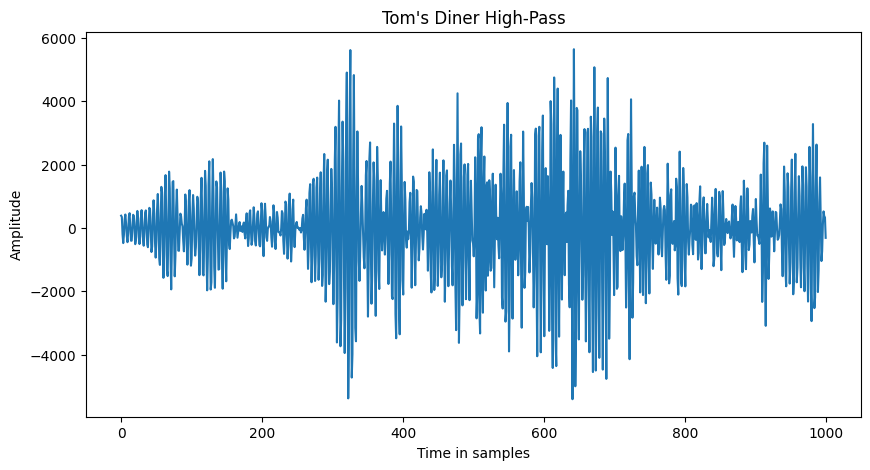

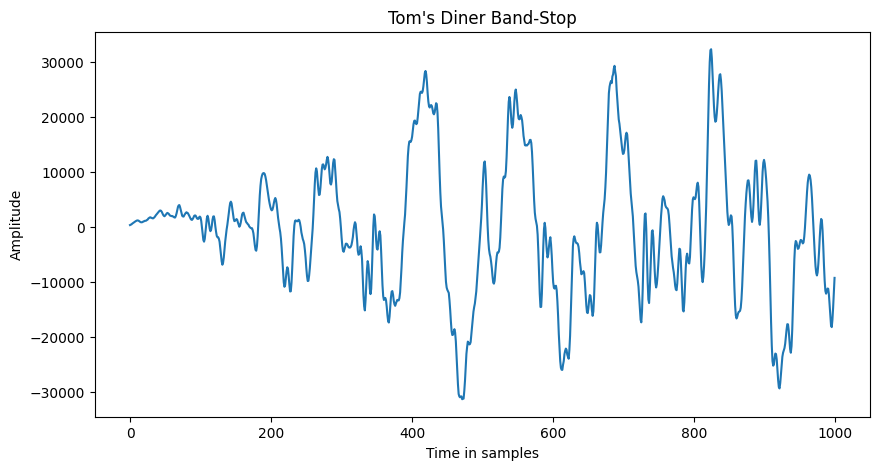

In [65]:

fig = plt.figure(figsize=(10, 5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Tom's Diner High-Pass")
# Keeps only the higher frequencies so we see many rapid, tightly packed oscillations
# also notice the maximum amplitude is much smaller
# this suggests that the originals signals energy was higher due to lower frequencies
# the lower frequency noises were loudest
plt.plot(high_pass_toms_diner[0:1000])
plt.savefig('plots/high_pass_toms_diner.png')
plt.show()

fig = plt.figure(figsize=(10, 5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Tom's Diner Band-Stop")
plt.plot(band_stop_toms_diner[0:1000])
plt.savefig('plots/band_stop_toms_diner.png')
plt.show()

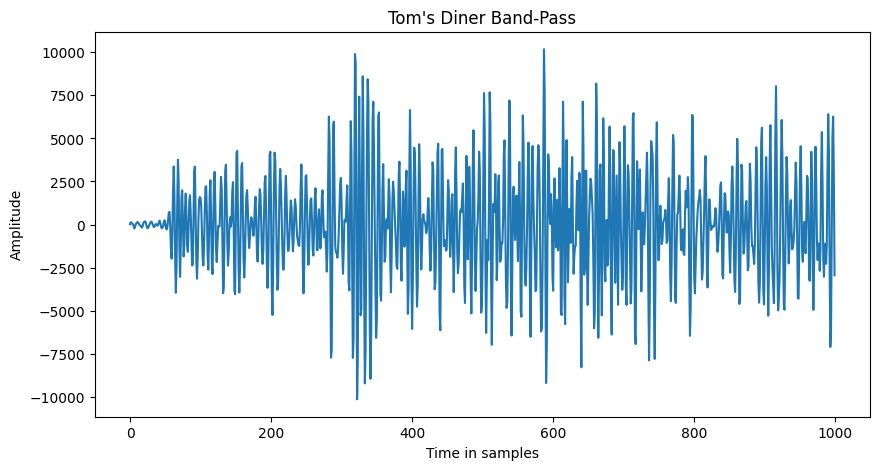

In [66]:
fig = plt.figure(figsize=(10, 5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Tom's Diner Band-Pass")
plt.plot(band_pass_toms_diner[0:1000])
plt.savefig('plots/band_pass_toms_diner.png')
plt.show()

In [42]:
# Create a melody
lptd = crude_filtering(tomsdiner[3*srate:5*srate], low_pass)
hptd = crude_filtering(tomsdiner[0:3*srate], high_pass)
bstd = crude_filtering(tomsdiner[0:2*srate], band_stop)
bptd = band_pass_crude_filtering(tomsdiner[2*srate:5*srate], band_pass)

filtered_toms_diner_melody = np.concatenate((lptd, hptd, lptd, lptd, bstd, bptd))
ipd.Audio(filtered_toms_diner_melody, rate=srate)

# save melody
save_audio_to_wav('audios/mag_spec_man_melody.wav', filtered_toms_diner_melody, srate)